# Logistic Regression vs XGBoost: Does a More Complex Model Always Perform Better?

I wanted to see if using a more complex model actually gives better results.

For this experiment, I'm comparing Logistic Regression and XGBoost on the same customer churn dataset. Both models will use the same data split and preprocessing so the comparison stays fair.

I'll compare them using accuracy, precision, recall, F1 score, and ROC-AUC.

Since the dataset has more non-churn customers than churn customers, I don't want to rely only on accuracy. Precision, recall, and F1 score will give us a better picture of how the models are actually performing.

The goal here is simple: see what the results say instead of assuming the more complex model will be better.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

## Loading the data

For this comparison, I'm using the Telco Customer Churn dataset. It contains customer details such as contract type, tenure, monthly charges, internet service, and whether the customer churned.

In [2]:
data_path = Path("../../data/Telco-Customer-Churn.csv")

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Preparing the data

Before training the models, I'm doing a small amount of cleanup.

`TotalCharges` contains a few blank values, so I'll convert it to a numeric column and fill those missing values with the median.

I'm also removing `customerID` since it's just an identifier and doesn't tell us anything useful about whether a customer will churn.

Finally, I'll convert the churn target into `0` and `1`.

In [3]:
# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Fill missing TotalCharges values
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

# customerID is only an identifier
df = df.drop(columns=["customerID"])

# Convert target to 0 and 1
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("Missing values:", df.isnull().sum().sum())
print("\nChurn distribution:")
print(df["Churn"].value_counts(normalize=True).round(3))

df.head()

Missing values: 0

Churn distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


## Train/test split

I'll use the same train and test data for both models. This is important because I don't want one model getting an easier test set than the other.

I'm also using a stratified split so the churn ratio stays roughly the same in both sets.

In [4]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

print("\nTraining churn rate:", round(y_train.mean(), 3))
print("Test churn rate:", round(y_test.mean(), 3))

Training rows: 5634
Test rows: 1409

Training churn rate: 0.265
Test churn rate: 0.265


## Preprocessing

The dataset contains both numerical and categorical features.

I'll standardize the numerical features and one-hot encode the categorical ones. The same preprocessing will be used for both models so that the comparison stays consistent.

In [5]:
numerical_features = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    col for col in X.columns
    if col not in numerical_features
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Numerical features: 4
Categorical features: 15


## Logistic Regression

I'll start with Logistic Regression as the simpler model in this comparison.

The preprocessing and model are kept in a single pipeline, so the transformations are learned from the training data and then applied consistently to the test data.

In [6]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=1000))
    ]
)

logistic_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pa

In [7]:
logistic_predictions = logistic_model.predict(X_test)

logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]

logistic_results = {
    "Accuracy": accuracy_score(y_test, logistic_predictions),
    "Precision": precision_score(y_test, logistic_predictions),
    "Recall": recall_score(y_test, logistic_predictions),
    "F1": f1_score(y_test, logistic_predictions),
    "ROC-AUC": roc_auc_score(y_test, logistic_probabilities)
}

for metric, value in logistic_results.items():
    print(f"{metric}: {value:.3f}")

Accuracy: 0.806
Precision: 0.657
Recall: 0.559
F1: 0.604
ROC-AUC: 0.842


## XGBoost

Now I'll run XGBoost using the same training data, test data, and preprocessing.

XGBoost can capture more complex relationships in the data than Logistic Regression, so I was curious to see whether that extra flexibility would actually improve the results here.

In [8]:
xgboost_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            XGBClassifier(
                random_state=42,
                eval_metric="logloss"
            )
        )
    ]
)

xgboost_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pa

In [9]:
xgboost_predictions = xgboost_model.predict(X_test)

xgboost_probabilities = xgboost_model.predict_proba(X_test)[:, 1]

xgboost_results = {
    "Accuracy": accuracy_score(y_test, xgboost_predictions),
    "Precision": precision_score(y_test, xgboost_predictions),
    "Recall": recall_score(y_test, xgboost_predictions),
    "F1": f1_score(y_test, xgboost_predictions),
    "ROC-AUC": roc_auc_score(y_test, xgboost_probabilities)
}

for metric, value in xgboost_results.items():
    print(f"{metric}: {value:.3f}")

Accuracy: 0.785
Precision: 0.606
Recall: 0.543
F1: 0.573
ROC-AUC: 0.825


## Comparing the results

Here are the results from both models on the same test set.

In [10]:
results = pd.DataFrame({
    "Logistic Regression": logistic_results,
    "XGBoost": xgboost_results
})

results.round(3)

,Logistic Regression,XGBoost
Accuracy,0.806,0.785
Precision,0.657,0.606
Recall,0.559,0.543
F1,0.604,0.573
ROC-AUC,0.842,0.825


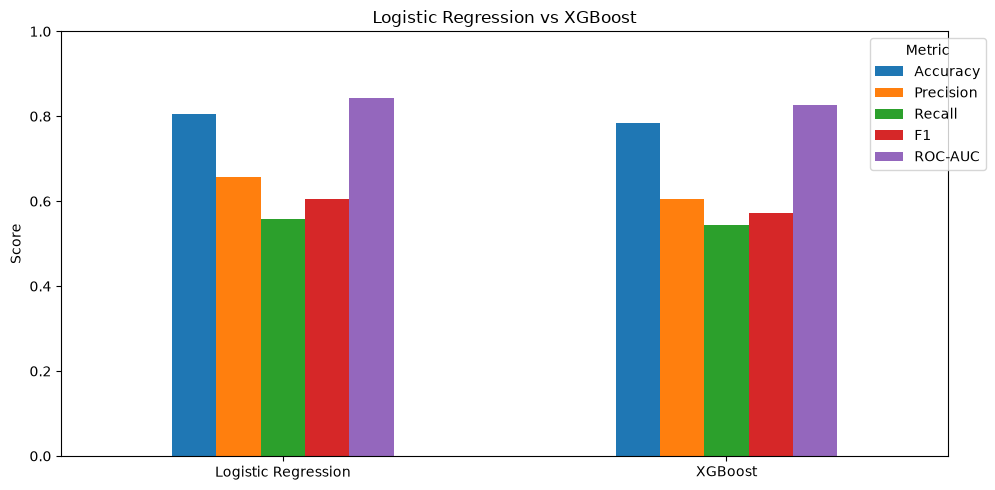

In [11]:
results.T.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Logistic Regression vs XGBoost")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Metric", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

## Checking the result with cross-validation

One test split isn't enough for me to say that one model is better.

To check whether the result holds across different parts of the data, I'll run 5-fold stratified cross-validation and compare the average scores.

In [12]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

logistic_cv = cross_validate(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

xgboost_cv = cross_validate(
    xgboost_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

In [13]:
cv_results = pd.DataFrame({
    "Logistic Regression": [
        logistic_cv["test_accuracy"].mean(),
        logistic_cv["test_precision"].mean(),
        logistic_cv["test_recall"].mean(),
        logistic_cv["test_f1"].mean(),
        logistic_cv["test_roc_auc"].mean()
    ],
    "XGBoost": [
        xgboost_cv["test_accuracy"].mean(),
        xgboost_cv["test_precision"].mean(),
        xgboost_cv["test_recall"].mean(),
        xgboost_cv["test_f1"].mean(),
        xgboost_cv["test_roc_auc"].mean()
    ]
}, index=[
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
])

cv_results.round(3)

,Logistic Regression,XGBoost
Accuracy,0.802,0.780
Precision,0.653,0.602
Recall,0.542,0.508
F1,0.592,0.551
ROC-AUC,0.846,0.822


## How consistent were the results?

Average scores are useful, but they don't show how much the results changed between folds.

So I'm also looking at the standard deviation across the five folds. A smaller value means the model's performance was more consistent across the different splits.

In [14]:
metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]

cv_summary = []

for metric in metrics:
    cv_summary.append({
        "Metric": metric.upper().replace("_", "-"),
        "Logistic Mean": logistic_cv[f"test_{metric}"].mean(),
        "Logistic Std": logistic_cv[f"test_{metric}"].std(),
        "XGBoost Mean": xgboost_cv[f"test_{metric}"].mean(),
        "XGBoost Std": xgboost_cv[f"test_{metric}"].std()
    })

cv_summary = pd.DataFrame(cv_summary)

cv_summary.round(3)

,Metric,Logistic Mean,Logistic Std,XGBoost Mean,XGBoost Std
0,ACCURACY,0.802,0.012,0.780,0.012
1,PRECISION,0.653,0.026,0.602,0.028
2,RECALL,0.542,0.041,0.508,0.023
3,F1,0.592,0.030,0.551,0.024
4,ROC-AUC,0.846,0.013,0.822,0.009


## What I found

I expected XGBoost to have an advantage here because it can capture more complex relationships in the data. But with the setup I tested, that wasn't the case.

Logistic Regression performed better on the test set across all five metrics. I then ran 5-fold cross-validation to check whether that result was just coming from one particular split. The overall pattern stayed the same there as well.

The cross-validation results were reasonably consistent across the folds. For example, Logistic Regression averaged 0.592 F1 with a standard deviation of 0.030, compared with 0.551 ± 0.024 for XGBoost.

This doesn't mean Logistic Regression is a better model than XGBoost in general. I used XGBoost without doing any serious hyperparameter tuning, and a different dataset or setup could produce a very different result.

What I take away from this experiment is that model complexity shouldn't be the starting point.

Start with a solid baseline, measure it properly, and make the more complex model prove that it's actually adding value.